# Lesson 3 · The agent and how it learns

Lessons 1 and 2 used hand-written controllers. Now the controller is a neural network,
and PPO adjusts its weights until it collects as much reward as it can. This lesson
covers:

1. the network: what goes in, what comes out;
2. how its output becomes a force, and why it is random during training;
3. what "as much reward as it can" means precisely (the discounted return and γ);
4. one PPO iteration in plain words;
5. the loss, term by term;
6. training a small agent yourself (about a minute);
7. reading a training log, healthy and failing;
8. which PPO settings you would ever change.

In [1]:
from lesson_tools import *
import tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from seqreach.config import Config
from seqreach.networks import Agent, RunningMeanStd
from seqreach.ppo import train
from seqreach.tracking import read_train_log
from seqreach import probes

use_style()

## 1 · The network

```
observation (16 numbers)
   │  normalise (running mean and SD of each input, learned during training)
   ▼
Linear 16→128, tanh  →  Linear 128→128, tanh          "trunk": feature extraction
   ▼
GRU, 128 units   ← hidden state h, carried from step to step, reset to 0 at trial start
   │
   ├──► actor:  Linear 128→1   = the MEAN force (in units of u_max)
   │            + one learned number, log σ, the exploration noise
   │
   └──► critic: Linear 128→1   = the VALUE: how much reward it expects from here on
```

The **GRU** is a recurrent layer: its 128-number hidden state `h` is its memory. Without
it the agent would only know the present observation, so it could not, for example,
remember how long it has been holding. `h` is also the "neural population" you analyse for
preparatory activity (lesson 4, and design doc §8.4).

The **actor** chooses actions and the **critic** judges situations. They share the trunk
and the GRU, and only their last layers differ.

**Where it lives:** `Agent` in [`seqreach/networks.py`](../seqreach/networks.py).
**Knobs (`agent.*`):** `recurrent` (False gives a memoryless MLP, the `mlp` arm),
`hidden_size`, `rnn_size`, `n_hidden_layers`, `activation`.

In [2]:
cfg = Config()
agent = Agent(obs_dim=16, act_dim=1, cfg_agent=cfg.agent, init_logstd=cfg.ppo.init_logstd)
print(agent)

counts = {}
for name, p in agent.named_parameters():
    part = name.split(".")[0]
    counts[part] = counts.get(part, 0) + p.numel()
pd.Series(counts, name="parameters").to_frame()


Agent(
  (trunk): Sequential(
    (0): Linear(in_features=16, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Tanh()
  )
  (rnn): GRU(128, 128)
  (actor_mean): Linear(in_features=128, out_features=1, bias=True)
  (critic): Linear(in_features=128, out_features=1, bias=True)
)


,parameters
actor_logstd,1
trunk,18688
rnn,99072
actor_mean,129
critic,129


## 2 · From network output to force

During training the agent does not output a force directly. It outputs the **mean** of a
bell curve, and the action is **sampled** from it:

```
action ~ Normal(mean, σ),   σ = exp(log σ)       then   force = action × u_max  (clipped to ±u_max)
```

The randomness is how it **explores**. It tries slightly different forces, and learning
makes the better ones more likely. At the start `log σ = −0.5`, so σ ≈ 0.61, which is
±5 force units of jitter. As training succeeds, σ shrinks. When you *analyse* an agent
you switch the randomness off and use the mean (`deterministic=True`), so its behaviour is
reproducible.

**See it.** A freshly built, untrained agent on 200 random trials:

In [4]:
torch.manual_seed(0)
fresh_norm = RunningMeanStd((16,))          # an observation normaliser that has seen no data yet
untrained = probes.rollout(agent, fresh_norm, cfg, {}, n_trials=200, seed=1, deterministic=False)
outcome = probes.outcome_breakdown(untrained)
pd.Series({k: outcome[k] for k in ("success_rate", "false_start_rate", "timeout_rate",
                                   "wall_contact_rate")}).round(3).to_frame("untrained agent")

,untrained agent
success_rate,0.060
false_start_rate,0.325
timeout_rate,0.615
wall_contact_rate,0.635


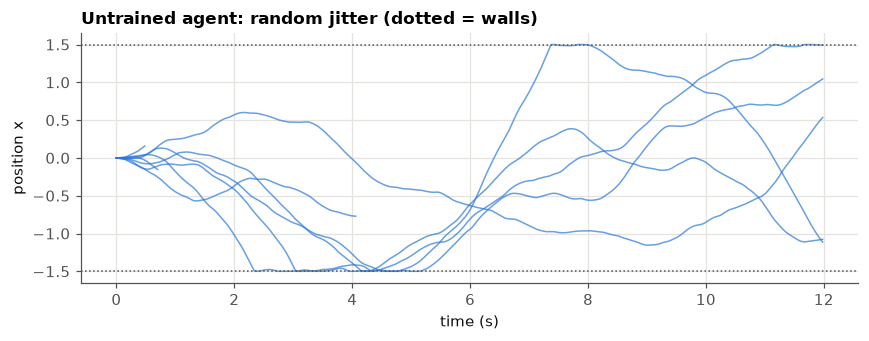

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for i in range(8):
    alive = untrained["alive"][:, i]
    ax.plot(np.flatnonzero(alive) * 0.02, untrained["x"][alive, i], color=BLUE, lw=1, alpha=0.7)
ax.axhline(1.5, color=INK_SOFT, lw=1, ls=":")
ax.axhline(-1.5, color=INK_SOFT, lw=1, ls=":")
ax.set_xlabel("time (s)")
ax.set_ylabel("position x")
ax.set_title("Untrained agent: random jitter (dotted = walls)")
plt.tight_layout()

It drifts at random: some trials false-start, many wander into a wall, and most time out.
Everything a trained agent does has to be learned from this starting point.

## 3 · What the agent is trying to maximise

The agent maximises the **discounted return**, the sum of future rewards, each weighted
by how far away it is:

```
G_t  =  r_t  +  γ·r_{t+1}  +  γ²·r_{t+2}  +  …        γ = ppo.gamma = 0.995
```

A reward k steps ahead is worth `γ^k` of its face value. Two ways to read a γ:

- **horizon** ≈ `1 / (1 − γ)` steps: roughly how far ahead rewards still count;
- **half-life** = `ln 0.5 / ln γ` steps: how far ahead a reward must be to be worth half.

In [5]:
dt = cfg.plant.dt
rows = []
for g in [0.995, 0.97, 0.90]:
    rows.append({"gamma": g,
                 "horizon (s)": 1 / (1 - g) * dt,
                 "half-life (s)": np.log(0.5) / np.log(g) * dt,
                 "T2's +20, 93 steps (1.9 s) away, is worth now": 20 * g ** 93})
pd.DataFrame(rows).set_index("gamma").round(3)

,horizon (s),half-life (s),"T2's +20, 93 steps (1.9 s) away, is worth now"
gamma,,,
0.995,4.000,2.766,12.548
0.970,0.667,0.455,1.177
0.900,0.200,0.132,0.001


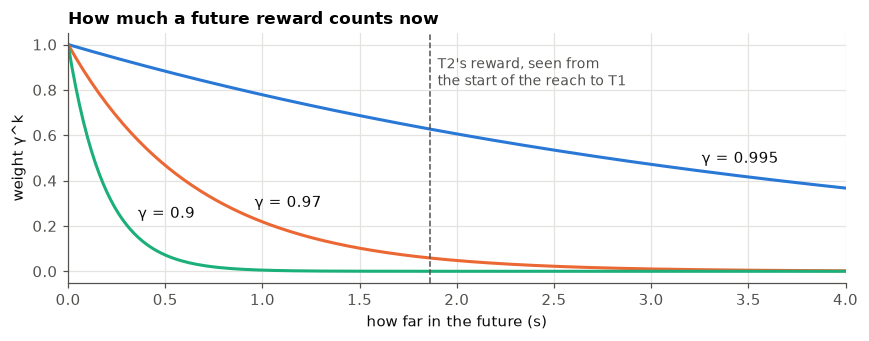

In [6]:
k = np.arange(0, 201)
fig, ax = plt.subplots()
for g, color, at_s in zip([0.995, 0.97, 0.90], [BLUE, ORANGE, AQUA], [3.2, 0.9, 0.3]):
    ax.plot(k * dt, g ** k, color=color)
    ax.text(at_s + 0.06, g ** (at_s / dt) + 0.03, f"γ = {g}", color=INK)  # label beside its curve
ax.axvline(93 * dt, color=INK_SOFT, lw=1, ls="--")
ax.text(93 * dt, 0.95, "  T2's reward, seen from\n  the start of the reach to T1", color=INK_SOFT,
        fontsize=9, va="top")
ax.set_xlim(0, 4)
ax.set_xlabel("how far in the future (s)")
ax.set_ylabel("weight γ^k")
ax.set_title("How much a future reward counts now")
plt.tight_layout()

The 93 steps come from a real trial in the design doc (§5.2): the time between choosing
the approach to T1 and collecting T2's reward. At γ = 0.995 T2's +20 still counts for
about 12 when the T1 reach is being chosen, so it is worth shaping that reach for T2. At
γ = 0.97 it counts for about 1, and at 0.90 for essentially nothing. **This is why γ is
an ablation axis (C7, `gamma097_sparse`)**: it controls whether the future target is
worth planning for at all.

**What the critic learns.** The critic's job is to predict `G_t` from the current
situation. Here is `G_t` along the hand-written 3-target trial from lesson 2, for two
values of γ:

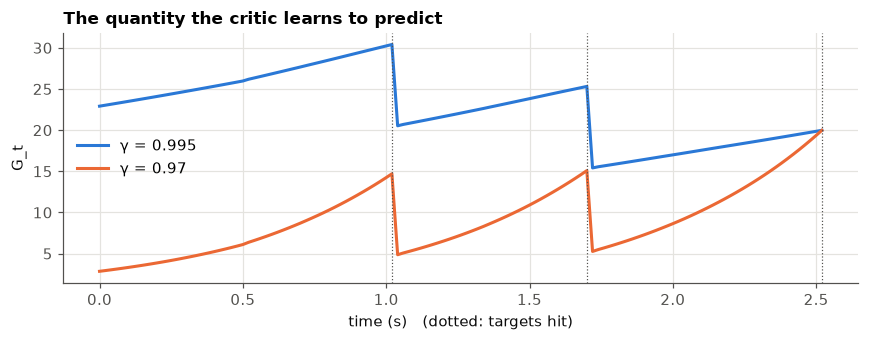

In [7]:
quiet = cfg.override({"plant.sigma_sdn": 0.0, "reward.shaping": "none"})
df, _ = run_trial(quiet, [0.5, -0.3, 0.2], pd_controller())

def discounted_return(rewards, gamma):
    '''G_t for every step, computed backwards: G_t = r_t + gamma * G_{t+1}.'''
    G, out = 0.0, np.zeros(len(rewards))
    for t in reversed(range(len(rewards))):
        G = rewards[t] + gamma * G
        out[t] = G
    return out

fig, ax = plt.subplots()
for g, color in zip([0.995, 0.97], [BLUE, ORANGE]):
    ax.plot(df.time_s, discounted_return(df.reward.values, g), color=color, label=f"γ = {g}")
hits = df[df.acquired]
for t_hit in hits.time_s:
    ax.axvline(t_hit, color=INK_SOFT, lw=0.8, ls=":")
ax.set_xlabel("time (s)   (dotted: targets hit)")
ax.set_ylabel("G_t")
ax.set_title("The quantity the critic learns to predict")
ax.legend()
plt.tight_layout()

With γ = 0.995 the value is high from the start, because all three targets already count.
With γ = 0.97 the value is low during the hold and only rises shortly before each target:
the far future hardly registers.

## 4 · One PPO iteration, in plain words

PPO (Proximal Policy Optimisation) repeats four steps:

1. **Collect.** Run the current (noisy) policy on 32 trials in parallel for 256 steps:
   8,192 steps of experience. Store each observation, action, its probability, the reward,
   and the critic's value estimate.
2. **Score.** For every step, compute the **advantage** `A_t`: how much better things
   turned out than the critic expected. Positive means that action was better than usual
   and should become more likely; negative means the opposite. (The estimator is GAE:
   `A_t = δ_t + γλ·δ_{t+1} + (γλ)²·δ_{t+2} + …`, with `δ_t = r_t + γ·V(s_{t+1}) − V(s_t)`
   and λ = 0.95.)
3. **Learn.** Take gradient steps on the loss (next section): 4 passes over the 8,192
   steps, each in 4 minibatches of 8 whole trials. The GRU needs whole sequences, so
   minibatches are cut by trial, not by step.
4. **Repeat.** 3,000,000 steps ÷ 8,192 ≈ 366 iterations.

**Where it lives:** `train` in [`seqreach/ppo.py`](../seqreach/ppo.py). The collect loop is
`for step in range(p.num_steps)`, and the blocks commented `# --- GAE` and `# --- update`
are steps 2 and 3.

## 5 · The loss, term by term

```
loss  =  policy_loss  −  ent_coef · entropy  +  vf_coef · value_loss
          (actor)         (exploration)          (critic)
```

**Policy loss (the actor).** For each stored step, compare how likely the action is under
the *new* weights with how likely it was when it was taken:
`ratio = π_new(a|s) / π_old(a|s)`. The objective is `A · ratio`: raise the probability of
actions with positive advantage, and lower it for negative. PPO's twist is **clipping**:
once the ratio moves outside `1 ± clip_coef` (±20%), there is no further gain from pushing
it. That keeps each update small, which is the "proximal" part.

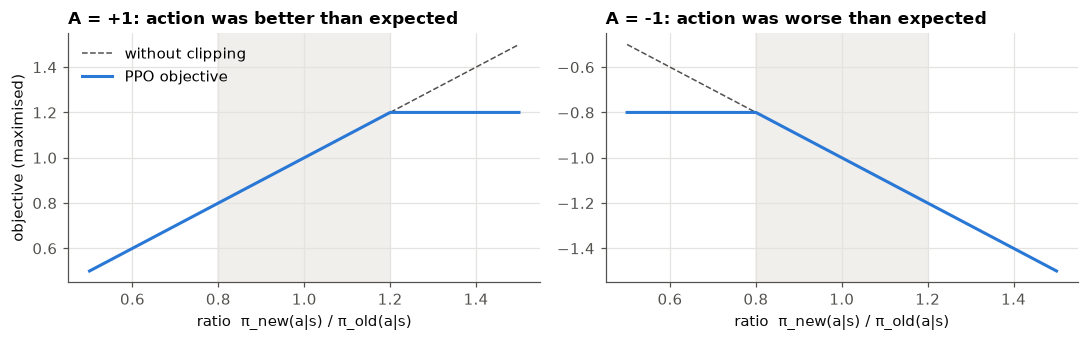

In [8]:
ratio = np.linspace(0.5, 1.5, 201)
eps = cfg.ppo.clip_coef
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, A in zip(axes, [+1.0, -1.0]):
    clipped = np.minimum(A * ratio, A * np.clip(ratio, 1 - eps, 1 + eps))
    ax.plot(ratio, A * ratio, color=INK_SOFT, lw=1, ls="--", label="without clipping")
    ax.plot(ratio, clipped, color=BLUE, label="PPO objective")
    ax.axvspan(1 - eps, 1 + eps, color=BAND, zorder=0)
    ax.set_title(f"A = {A:+.0f}: action was {'better' if A > 0 else 'worse'} than expected")
    ax.set_xlabel("ratio  π_new(a|s) / π_old(a|s)")
axes[0].set_ylabel("objective (maximised)")
axes[0].legend(loc="upper left")
plt.tight_layout()

Left: for a good action, the objective rises as its probability goes up, then goes flat
past +20%, so there is no reason to push further this round. Right: the mirror image for
a bad action. (The code minimises the negative of this, so it is called a loss.)

**Value loss (the critic).** `½·(V(s) − G)²`: the critic's prediction error on the returns
it just saw, also clipped. A better critic gives better advantages, and so better actor
updates.

**Entropy bonus (exploration).** For a Gaussian policy the entropy is
`½·ln(2πe) + log σ`. It is 0.92 at the start (log σ = −0.5) and falls as σ shrinks.
Rewarding entropy slightly (`ent_coef = 0.003`) slows that shrinking, so the agent keeps
trying things. Too little, and it commits early to a mediocre solution. Too much, and it
never settles.

Four normalisations run in the background: observations (the `obs_rms` saved with every
checkpoint, which is needed to run the agent later), rewards (divided by the running spread
of returns), advantages (per minibatch), and gradient clipping (`max_grad_norm`).

> **The loss is not a progress bar.** In supervised learning the loss falls as the model
> improves. In RL the policy loss hovers near zero by construction, and the value loss
> rises and falls as returns change. Judge training by the diagnostics in section 7.

## 6 · Train a small agent yourself

This trains the default configuration for 500,000 steps instead of 3,000,000. It takes
about a minute on this Mac. It writes to a throwaway temporary folder, not `runs/`.

Each printed line is one PPO iteration: `ret` = average task return of recent trials,
`succ` = success rate, `hits` = fraction of targets hit, `nT` = average number of
targets per trial (the curriculum), `wall` = fraction of trials touching the wall,
`ev` = how well the critic predicts returns (explained variance), `sps` = steps per second.

In [9]:
toy = Config().override({
    "ppo.total_timesteps": 500_000,     # a real run is 3,000,000
    "video.enabled": False,             # no GIFs during training
    "wandb.enabled": False,             # no online tracking for a toy
    "torch_threads": 1,                 # one thread is fastest for this network
})
toy.exp_name, toy.seed = "lesson_toy", 1
run_dir = Path(tempfile.mkdtemp(prefix="lesson_toy_"))

toy_agent, toy_obs_rms, _ = train(toy, run_dir, log_every=10)

it   10/61 step    81,920 ret  -11.36 succ 0.47 hits 0.48 nT 1.10 wall 0.03 ev  0.50 sps 11188


it   20/61 step   163,840 ret   -2.00 succ 0.63 hits 0.66 nT 1.20 wall 0.04 ev  0.83 sps 11210


it   30/61 step   245,760 ret    1.99 succ 0.71 hits 0.77 nT 1.31 wall 0.07 ev  0.97 sps 11249


it   40/61 step   327,680 ret    6.25 succ 0.78 hits 0.82 nT 1.42 wall 0.00 ev  0.95 sps 11254


it   50/61 step   409,600 ret    6.67 succ 0.76 hits 0.84 nT 1.52 wall 0.00 ev  0.91 sps 11260


it   60/61 step   491,520 ret    1.93 succ 0.60 hits 0.77 nT 1.63 wall 0.00 ev  0.94 sps 11285


it   61/61 step   499,712 ret    2.48 succ 0.62 hits 0.78 nT 1.64 wall 0.01 ev  0.97 sps 11287


Compare its learning curve with the first 500k steps of the real baseline run
(`runs/baseline_s1`, same config, same seed, but trained with the full 3M schedule):

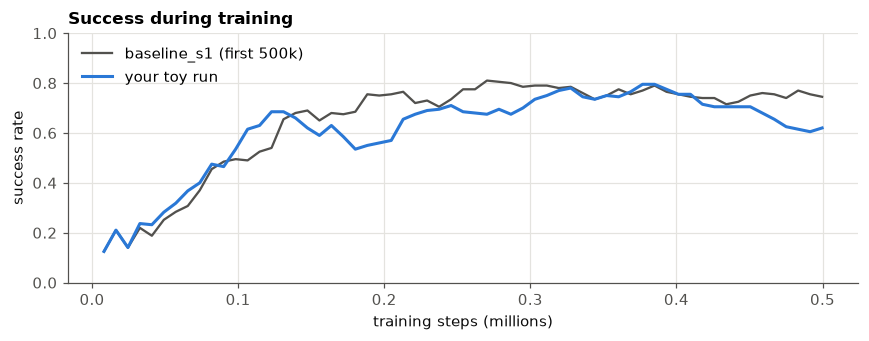

In [10]:
toy_log = pd.DataFrame(read_train_log(run_dir))
base_log = pd.DataFrame(read_train_log(RUNS / "baseline_s1"))

fig, ax = plt.subplots()
early = base_log[base_log.global_step <= 500_000]
ax.plot(early.global_step / 1e6, early.success_rate, color=INK_SOFT, lw=1.5, label="baseline_s1 (first 500k)")
ax.plot(toy_log.global_step / 1e6, toy_log.success_rate, color=BLUE, label="your toy run")
ax.set_xlabel("training steps (millions)")
ax.set_ylabel("success rate")
ax.set_ylim(0, 1)
ax.legend()
ax.set_title("Success during training")
plt.tight_layout()

The two runs share config and seed, so they start out identical. They drift apart because the toy run's
learning rate decays to zero over 500k steps instead of 3M. Now test the
toy agent on the full task mixture, with noise off and the policy mean:

In [11]:
test = probes.rollout(toy_agent, toy_obs_rms, probes.probe_config(toy), {}, n_trials=512, seed=123)
o = probes.outcome_breakdown(test)
print("success by number of targets:", {k: round(v, 2) for k, v in o["success_by_n_targets"].items()})
print(f"overall {o['success_rate']:.2f}   timeouts {o['timeout_rate']:.2f}   "
      f"false starts {o['false_start_rate']:.2f}")

success by number of targets: {1: 1.0, 2: 0.3, 3: 0.0}
overall 0.30   timeouts 0.61   false starts 0.09


Look at success **by number of targets**. An agent that has not finished learning usually
does well on 1-target trials and worse on longer sequences. That is why the analysis always
splits success this way (lesson 4). A real run needs the full 3M steps, and 8 seeds.

From the terminal, a real run is one command. Always add `--wandb` so it is tracked:

```bash
.conda/bin/python 1D/scripts/train.py --name baseline --timesteps 3000000 --seed 1 --wandb
```

It writes `1D/runs/baseline_s1/` containing:

In [12]:
sorted(p.name for p in (RUNS / "baseline_s1").iterdir())

['analysis',
 'analyze.log',
 'checkpoint.pt',
 'config.yaml',
 'stdout.log',
 'train_log.jsonl',
 'videos',
 'wandb']

| file | what |
|---|---|
| `config.yaml` | the exact config used |
| `train_log.jsonl` | one line of diagnostics per iteration (section 7) |
| `checkpoint.pt` | the trained weights, the observation normaliser, and the config |
| `stdout.log` | what was printed |
| `videos/`, `wandb/` | GIFs and W&B's local copy |
| `analysis/` | written later by `scripts/analyze.py` (lesson 4) |

## 7 · Reading a training log

Here are two real 3M-step runs side by side: `baseline_s1`, which learned the task, and
`stop_at_targets_s3`, which did not. (That arm requires stopping at every target, lesson 2.)

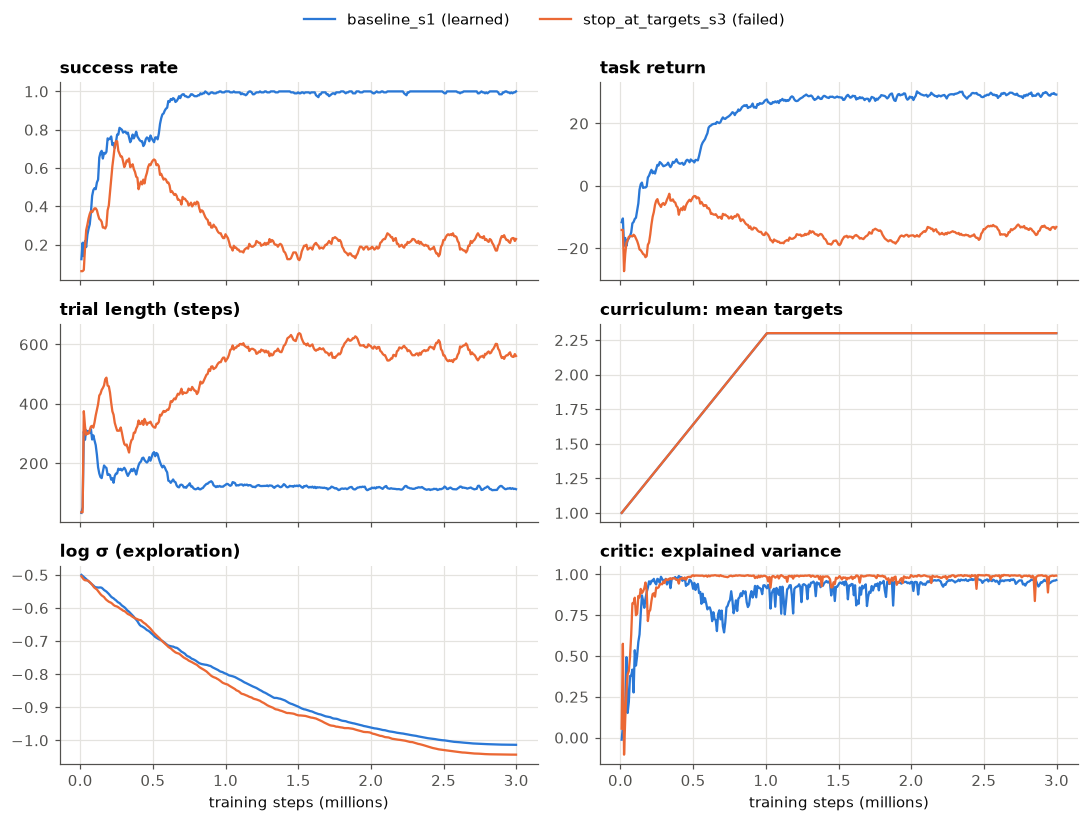

In [13]:
logs = {"baseline_s1 (learned)": pd.DataFrame(read_train_log(RUNS / "baseline_s1")),
        "stop_at_targets_s3 (failed)": pd.DataFrame(read_train_log(RUNS / "stop_at_targets_s3"))}
panels = [("success_rate", "success rate"), ("episodic_return_task", "task return"),
          ("episodic_length", "trial length (steps)"), ("mean_n_targets", "curriculum: mean targets"),
          ("logstd", "log σ (exploration)"), ("explained_variance", "critic: explained variance")]

fig, axes = plt.subplots(3, 2, figsize=(10, 7.5), sharex=True)
for ax, (col, title) in zip(axes.flat, panels):
    for (name, log), color in zip(logs.items(), [BLUE, ORANGE]):
        ax.plot(log.global_step / 1e6, log[col], color=color, lw=1.5, label=name)
    ax.set_title(title)
for ax in axes[-1]:
    ax.set_xlabel("training steps (millions)")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=2)
plt.tight_layout(rect=(0, 0, 1, 0.95))

In [14]:
end = {name: log.tail(20).mean(numeric_only=True) for name, log in logs.items()}
cols = ["success_rate", "episodic_return_task", "episodic_return", "episodic_length",
        "explained_variance", "logstd", "approx_kl", "clipfrac", "wall_rate"]
pd.DataFrame(end).loc[cols].round(3)

,baseline_s1 (learned),stop_at_targets_s3 (failed)
success_rate,0.995,0.218
episodic_return_task,29.316,-13.872
episodic_return,29.673,-12.656
episodic_length,115.333,570.601
explained_variance,0.954,0.978
logstd,-1.013,-1.043
approx_kl,0.002,0.000
clipfrac,0.004,0.000
wall_rate,0.000,0.023


How to read each diagnostic (the table shows the average of the last 20 iterations):

| diagnostic | healthy | what it tells you |
|---|---|---|
| `success_rate`, `hit_fraction` | → about 1.0 | the task is being solved |
| `episodic_return_task` | rises, then plateaus (≈ 29 here) | progress on the real objective. Prefer it to `episodic_return`, which includes shaping income |
| `episodic_length` | falls to ≈ 110 steps | a failing run that creeps toward `max_steps` is **timing out** |
| `mean_n_targets` | climbs 1.0 → 2.3 over the first 1M steps | the curriculum. A success dip while it climbs is the task getting harder, not the agent getting worse |
| `logstd` / `entropy` | decrease slowly | exploration shrinking as the policy commits |
| `explained_variance` | → 0.9 or more | the critic predicts returns well |
| `approx_kl`, `clipfrac` | small (mid-training below ≈ 0.01 and ≈ 0.1) | the size of each update, falling toward 0 at the end as the learning rate decays. Large values mean unstable learning |
| `wall_rate` | ≈ 0 | a high value means the policy is parking at the wall |

**The failing run is instructive.** Its trial length climbs to several hundred steps out
of its 700-step budget: it is timing out, not doing something else. Its critic's explained
variance is about 0.98, the *higher* of the two, because a critic can predict failure
perfectly. **A good critic is not a good agent.** When a run fails, look at failure
attribution and the time budget (results doc §2) before touching PPO settings.

## 8 · PPO settings: which ones you would ever touch

In [15]:
show(Config().ppo)

,value
key,
total_timesteps,2000000
num_envs,32
num_steps,256
learning_rate,0.0003
anneal_lr,True
gamma,0.995
gae_lambda,0.95
num_minibatches,4
update_epochs,4


| key | default | what it does | touch it? |
|---|---|---|---|
| `gamma` | 0.995 | discount (section 3) | **yes, it is a science knob** (C7) |
| `total_timesteps` | 2,000,000 | training length. The scripts pass `--timesteps 3000000` | yes, when an arm learns slowly |
| `ent_coef` | 0.003 | exploration bonus | rarely. The results doc (§8) shows it can flip a result's sign |
| `learning_rate`, `anneal_lr` | 3e-4, True | step size, decayed linearly to 0 | rarely |
| `num_envs` × `num_steps` | 32 × 256 | experience per iteration (8,192 steps) | rarely. `num_envs` must be divisible by `num_minibatches` |
| `update_epochs`, `num_minibatches` | 4, 4 | how many gradient steps per iteration | no |
| `clip_coef`, `clip_vloss` | 0.2, True | PPO clipping | no |
| `gae_lambda` | 0.95 | advantage smoothing | no |
| `vf_coef`, `max_grad_norm` | 0.5, 0.5 | critic weight in the loss, gradient clipping | no |
| `norm_obs`, `norm_reward`, `norm_adv` | True | the normalisations | no |
| `init_logstd` | −0.5 | starting exploration noise | no |

The science lives in `task.*`, `reward.*`, `plant.*` and `ppo.gamma`. The rest is the
learning machinery: leave it at CleanRL's defaults unless you have a specific reason, and
change one thing at a time.

## Check yourself

**1.** Why does a checkpoint store `obs_rms` (the observation normaliser) as well as the
network weights?

<details><summary>Answer</summary>

The network was trained on *normalised* observations. Feed it raw ones and every input is
on a different scale from what it learned on, so its behaviour is meaningless. `load_agent`
returns `obs_rms` for exactly this reason.
</details>

**2.** `stop_at_targets_s3` has the higher explained variance but fails most trials. How?

<details><summary>Answer</summary>

Explained variance measures how well the critic *predicts* returns, not how good they are.
Consistently timing out is very predictable.
</details>

**3.** Using the table in section 3: at γ = 0.97, roughly what is T2's +20 worth when the
reach to T1 is chosen? What does that predict?

<details><summary>Answer</summary>

About 1.2. The agent has little reason to shape the T1 reach for T2, so it predicts
weaker lookahead. The provisional result in the results doc (§7) is a CI near zero, but
with T2 still influencing the trajectory in other ways.
</details>

**4.** A new arm ends training at 0.3 success, with trial length near `max_steps`. What do
you check first?

<details><summary>Answer</summary>

Whether it is budget-limited: its failures are timeouts, so raise `task.max_steps` (and
check failure attribution in lesson 4). Do not start by tuning PPO settings.
</details>

**5.** `logstd` went from −0.5 to −1.0 during training. What changed?

<details><summary>Answer</summary>

The exploration noise σ fell from 0.61 to 0.37 (in units of u_max). The policy became more
certain, which is normal as it converges.
</details>

## Summary

- **The agent** is a small network: trunk → GRU (memory) → actor (mean force + learned
  noise) and critic (expected future reward).
- **During training actions are sampled**, which is how it explores. For analysis the
  noise is off and the mean is used.
- **It maximises the discounted return.** γ sets how far ahead rewards count; at 0.995 the
  next target is worth planning for, and at 0.97 barely.
- **PPO** collects 8,192 steps, scores each with an advantage, and nudges action
  probabilities toward the better actions, clipped to ±20% per iteration.
- **Read training by its diagnostics**, not its loss. Watch task return, success, trial
  length (timeouts), the curriculum, exploration noise, and the critic.

Next: **Lesson 4 · Measuring a trained agent**.